# 03 · Signatures — embryonic module scores
Score the three embryonic modules (Gast, pSom, Crest) with `score_genes` against the union control pool, and map them on the manifold.

**Gate 2:** does the embryonic pattern appear — a Gast/pSom hub diverging into two arms, with Crest at a tip? Read the geography off the raw signature embeddings.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
sc.settings.verbosity = 1

In [2]:
name = os.path.split(os.getcwd())[1]
cat  = os.path.split(os.path.split(os.getcwd())[0])[1]
pth  = os.path.join(*(['..']*4))
pth_data = os.path.join(pth, 'data')
pth_in   = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out  = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb   = os.path.join(pth_out, 'colorbars')
os.makedirs(pth_cb, exist_ok = True)

In [3]:
# load manifold data from h5ad file
adata = sc.read_h5ad(os.path.join(pth_in, 'manifold.h5ad')); adata

In [4]:
# build module dictionary (names -> genes); union is the score_genes control pool
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
get_feat = lambda fn: pd.read_csv(fn).hsapiens.drop_duplicates()
feat_dict = {get_src(fn): get_feat(fn) for fn in feat_fn}
g_ref = feat_dict['union'][feat_dict['union'].isin(adata.var_names)].copy()
labels = {'GSE162534': 'Gast', 'GSE229103': 'pSom', 'rRNAModifications': 'Crest'}
for src, df_src in feat_dict.items():
    if src != 'union':
        g = df_src[df_src.isin(adata.var_names)].copy()
        sc.tl.score_genes(adata, gene_list = g, score_name = labels[src],
                          ctrl_as_ref = False, gene_pool = g_ref, random_state = 1234)
        print(labels[src], g.size, g_ref.size)

Gast 76 224
pSom 88 224
Crest 101 224


### Gastrulation signature

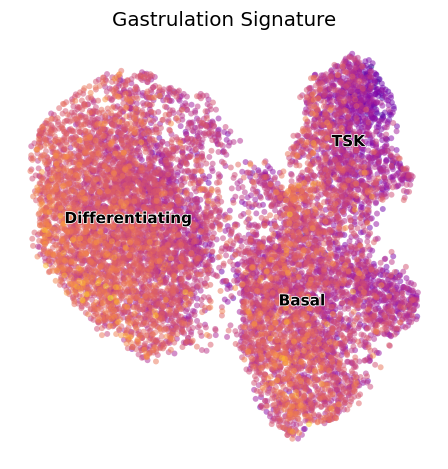

In [5]:
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'Gast', cmap = 'plasma', alpha = .5,
           size = 60, colorbar_loc = None, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 60, alpha = 0,
           legend_loc = 'on data', legend_fontoutline = 1,
           frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Gastrulation Signature', size = 13)
fig.savefig(os.path.join(pth_out, 'Gast_signature.pdf'), bbox_inches = 'tight')

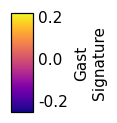

In [6]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Gast\nSignature')
ticks = np.asarray([-.2, 0, .2])
cb.set_ticks(ticks, labels = ticks)
cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'Gast_colorbar.pdf'), bbox_inches = 'tight')

### Somitogenesis (pSom) signature

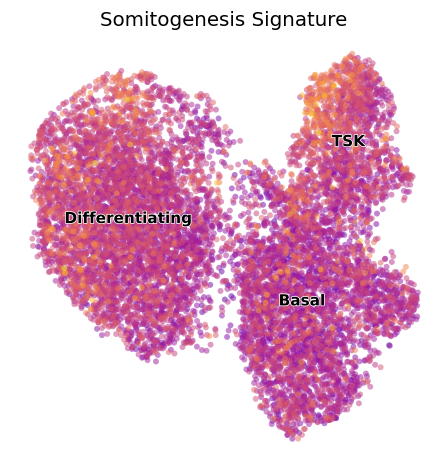

In [7]:
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'pSom', cmap = 'plasma', alpha = .5,
           size = 60, colorbar_loc = None, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 60, alpha = 0,
           legend_loc = 'on data', legend_fontoutline = 1,
           frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Somitogenesis Signature', size = 13)
fig.savefig(os.path.join(pth_out, 'pSom_signature.pdf'), bbox_inches = 'tight')

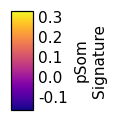

In [8]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('pSom\nSignature')
ticks = np.asarray([-.1, 0, .1, .2, .3])
cb.set_ticks(ticks, labels = ticks)
cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'pSom_colorbar.pdf'), bbox_inches = 'tight')

### Neural crest (Crest) signature

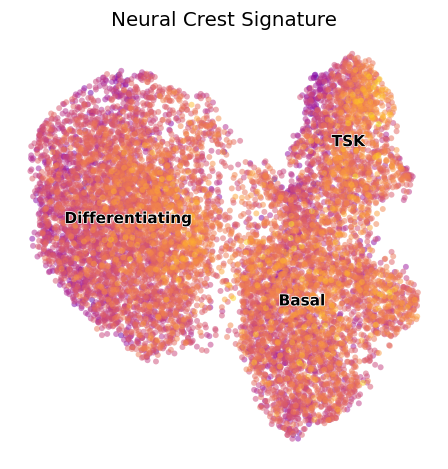

In [9]:
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'Crest', cmap = 'plasma', alpha = .5,
           size = 60, colorbar_loc = None, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'celltype', size = 60, alpha = 0,
           legend_loc = 'on data', legend_fontoutline = 1,
           frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Neural Crest Signature', size = 13)
fig.savefig(os.path.join(pth_out, 'Crest_signature.pdf'), bbox_inches = 'tight')

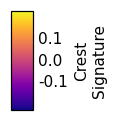

In [10]:
fig = plt.figure(figsize = (.66, 1))
cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax)
cb.ax.tick_params(which = 'both', size = 0)
cb.set_label('Crest\nSignature')
ticks = np.asarray([-.1, 0, .1])
cb.set_ticks(ticks, labels = ticks)
cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'Crest_colorbar.pdf'), bbox_inches = 'tight')

**Gate 2 geography.** Out of the basal hub, **Gast** rises into the differentiation arm while **pSom** rises into the TSK arm — the two modules diverge in opposite directions (the cross-repression axis). **Crest** is a terminal readout: elevated toward the basal/TSK side and depleted at the Gast-leaning differentiation tip, i.e. uncoupled from the Gast/pSom axis rather than tracking one arm. The embryonic hub-and-two-arms pattern is present → **Gate 2 GO (branching)**.

In [11]:
# save signatures data to h5ad file
adata.write(os.path.join(pth_in, 'signatures.h5ad'))